# 00. ベースライン: 元の特徴量だけのLightGBM

**このノートブックの目的:** コンペで最初から与えられた元の特徴量だけでモデルを作り、以降の施策(特徴量・モデル・アンサンブル)を比べる土台のスコアを決める。

**使うもの:** `data/train.csv`・`data/test.csv`(Kaggleから取得)。

**結論:** 元の特徴量21個を単変量AUCの高い順に1つずつ足すと、20個目まで改善し、性別だけは悪化した。性別を除く**20個を土台**にした(OOF AUC 0.95846、Private LB 0.95910)。
このOOFは 01_EDA の7節でも使う。

In [1]:
import sys

sys.path.insert(0, "../src")  # 共通処理(features.py・modeling.py・public_oof.py)を読み込む
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

import features
import modeling

plt.rcParams["font.family"] = "Meiryo"  # グラフの日本語ラベル用
DATA = features.DATA_DIR
train, test = features.load_train_and_test()
y = train[features.TARGET].astype(int).values
print(f"train {len(train):,}行・test {len(test):,}行、満足率 {y.mean():.3f}")

train 699,635行・test 299,844行、満足率 0.444


## 1. 元の特徴量

コンペのデータは、乗客1人が1行のアンケート結果。目的変数は `satisfaction`(満足=1、不満=0。満足の割合は約44%)。

| 種類 | 特徴量 |
|---|---|
| 乗客 | 性別(Gender)、年齢(Age)、顧客区分(Customer Type: 常連 / 常連でない) |
| 旅行 | 旅行目的(Type of Travel: 出張 / 私用)、座席クラス(Class: ビジネス / エコノミー / エコノミープラス)、飛行距離(Flight Distance) |
| 遅延 | 出発遅延(分)、到着遅延(分、292行が欠損) |
| サービス評価(13項目、0〜5点) | Wi-Fi(機内)、時刻の便利さ、オンライン予約、ゲートの場所、食事、オンライン搭乗、座席、機内エンタメ、機内サービス、足元の広さ、手荷物の扱い、チェックイン、清潔さ |

In [2]:
original_features = features.ORIGINAL_FEATURES_BY_UNIVARIATE_AUC
summary = pd.DataFrame({"型": train[original_features].dtypes.astype(str), "値の種類": train[original_features].nunique(),
                        "欠損": train[original_features].isna().sum(), "最小": train[original_features].min(numeric_only=True),
                        "最大": train[original_features].max(numeric_only=True)})
print(f"元の特徴量 {len(original_features)}個")
summary

元の特徴量 21個


,型,値の種類,欠損,最小,最大
Age,int64,75,0,7.0,85.0
Arrival Delay in Minutes,float64,168,292,0.0,491.0
Baggage handling,int64,5,0,1.0,5.0
Checkin service,int64,6,0,0.0,5.0
Class,str,3,0,NaN,NaN
Cleanliness,int64,6,0,0.0,5.0
Customer Type,str,2,0,NaN,NaN
Departure Delay in Minutes,int64,167,0,0.0,489.0
Departure/Arrival time convenient,int64,6,0,0.0,5.0
Ease of Online booking,int64,6,0,0.0,5.0


## 2. 元の特徴量を1つずつ足して、効くものを選ぶ

**目的:** どの元の特徴量が効くかを、同じ物差しで1つずつ確かめる。単独では弱くても、ほかと組み合わせると効く特徴量もあるので、単変量AUCだけでは決めない。

**検証方法:**
- モデルはLightGBM(既定のハイパラ、学習率0.05)。欠損やカテゴリをそのまま扱え、70万行でも数分で学習できるので、比べる道具に向いている。
- 評価は5分割の交差検証(StratifiedKFold、seed 42)。各行を、その行を学習していないモデルで予測した値(OOF)をつなげ、AUCで測る。木の本数は検証foldのAUCが100回伸びなくなったところで止める。
- 足す順は、単変量AUC(その特徴量の値ごとの満足率だけで並べ分けたときのAUC、01_EDAの1節)の高い順。
- 1個から21個まで、21回学習する(1回あたり約3分)。

In [3]:
results, X_test_baseline = [], None
for n in range(1, len(original_features) + 1):
    used = original_features[:n]
    X, X_test = features.build_train_and_test_tables(train, test, feature_names=[], base_features=used)
    oof, test_prediction = modeling.cross_validate_lightgbm(X, y, X_test=X_test if n == 20 else None, verbose=False)
    results.append({"個数": n, "足した特徴量": used[-1], "OOF AUC": roc_auc_score(y, oof)})
    if n == 20:
        np.save(DATA / "oof_lightgbm_baseline.npy", oof)
        baseline_test_prediction = test_prediction
    print(f"{n:2d}個 +{used[-1]}: OOF AUC {results[-1]['OOF AUC']:.6f}")
results = pd.DataFrame(results)
results["前からの伸び"] = results["OOF AUC"].diff()

 1個 +Online boarding: OOF AUC 0.853818


 2個 +Class: OOF AUC 0.902761


 3個 +Inflight entertainment: OOF AUC 0.920646


 4個 +Inflight wifi service: OOF AUC 0.944777


 5個 +Seat comfort: OOF AUC 0.946942


 6個 +Flight Distance: OOF AUC 0.948901


... (11 outputs left out)

18個 +Departure/Arrival time convenient: OOF AUC 0.958395


19個 +Arrival Delay in Minutes: OOF AUC 0.958432


20個 +Departure Delay in Minutes: OOF AUC 0.958459


21個 +Gender: OOF AUC 0.958440


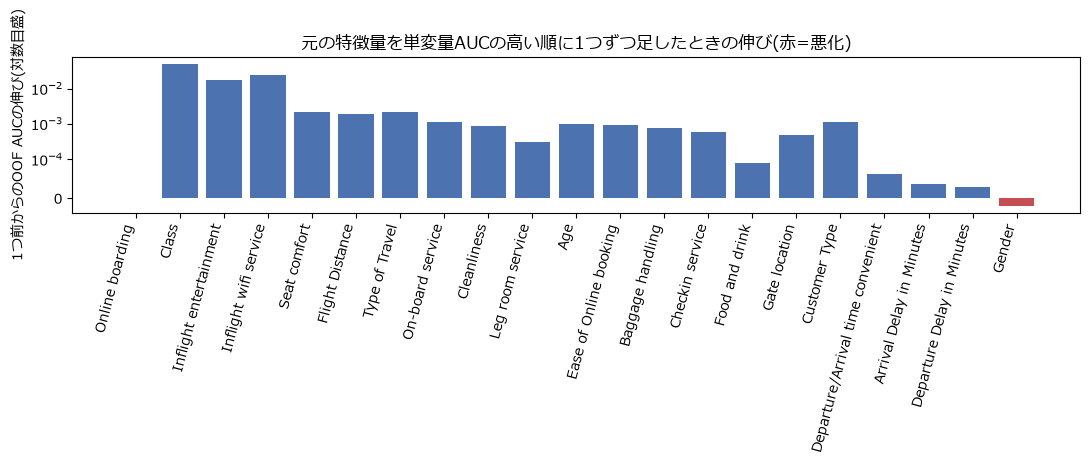

,個数,足した特徴量,OOF AUC,前からの伸び
0,1,Online boarding,0.853818,NaN
9,10,Leg room service,0.953355,0.000298
15,16,Gate location,0.957201,0.000483
16,17,Customer Type,0.958332,0.001131
19,20,Departure Delay in Minutes,0.958459,0.000028
20,21,Gender,0.958440,-0.000019


In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(results["足した特徴量"], results["前からの伸び"].fillna(0), color=np.where(results["前からの伸び"] < 0, "#C44E52", "#4C72B0"))
ax.set_yscale("symlog", linthresh=1e-4)
ax.set_ylabel("1つ前からのOOF AUCの伸び(対数目盛)")
ax.set_title("元の特徴量を単変量AUCの高い順に1つずつ足したときの伸び(赤=悪化)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()
results.iloc[[0, 9, 15, 16, 19, 20]].round(6)

#### 結果と考察

- 20個目(出発遅延)まではすべて改善した。単独では弱い顧客区分(単変量AUC 0.586)も、足すと+0.00113と大きく伸びた。客層ごとにサービス評価の効き方が違い、その切り替えに使われたと考えられる(01_EDAの5節で確かめた)。
- 性別だけは−0.00002で、効かなかったので外した。
- この判定はseed 42の1回だけで行った(採否の基準を設ける前だったため。基準は 03_feature_engineering の「採否の判定」)。性別は、のちに特徴量を29個に増やした土台でも試し直したが、−0.000053で効かなかった(これも1seed)。

## 3. ベースラインの提出ファイル

性別を除く20個のモデルで、testを予測する(5つのfoldのモデルの平均)。

In [5]:
submission = pd.DataFrame({"id": test["id"], "satisfaction": baseline_test_prediction})
submission.to_csv(DATA / "submission_baseline.csv", index=False)
print(f"OOF AUC {results.loc[19, 'OOF AUC']:.5f} / 提出ファイル data/submission_baseline.csv({len(submission):,}行)")

OOF AUC 0.95846 / 提出ファイル data/submission_baseline.csv(299,844行)


## Summary

| 決めたこと | 値 |
|---|---|
| 土台にする特徴量 | 元の特徴量21個から性別を除いた20個 |
| 比べ方 | LightGBM・5分割(StratifiedKFold、seed 42)のOOF AUC |
| ベースラインのスコア | OOF AUC 0.95846 / Private LB 0.95910(上位76%) |

次は 01_EDA で、データの偏りから特徴量の着想を探す。